# Question 2: did metros that built more see slower price growth?

**Permits per 1,000 residents** is housing units permitted over the trailing 12 months per 1,000 residents (Census BPS,
ACS population); the December row is the calendar year. Here it is averaged over 2016–2025 and set against ZHVI growth
from December 2015 to December 2025, with a least-squares line (`numpy.polyfit`). Source: `gold.mart_metro_month`.

Caveats: 11 metros is a small sample, and a correlation is not a supply effect: fast-growing metros both build more and
attract demand. Permits are not completions; they lead them by one to two years. Austin, the top builder, has a large
pull on the line, so it is also fitted without it.

In [1]:
import common as c
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

In [2]:
d, fit = c.permits_vs_growth((2016, 2025), (2015, 2025))
top = d.permits_per_1000.idxmax()
rest = d.drop(top)
fit_rest = dict(
    zip(("slope", "intercept"), np.polyfit(rest.permits_per_1000, rest.zhvi_growth, 1))
)
fit_rest["r"] = np.corrcoef(rest.permits_per_1000, rest.zhvi_growth)[0, 1]
display(d.sort_values("permits_per_1000", ascending=False))
pd.DataFrame({"all 11 metros": fit, f"without {top}": fit_rest}).T

,permits_per_1000,zhvi_growth
metro,,
Austin,15.378,0.570
Raleigh,12.677,0.851
Nashville,11.492,1.040
Orlando,9.877,1.002
Charlotte,9.779,1.113
Dallas-Fort Worth,8.691,0.860
Phoenix,8.249,0.977
Denver,7.261,0.720
Tampa,6.814,1.079


,slope,intercept,r
all 11 metros,-0.031,1.224,-0.547
without Austin,-0.006,1.020,-0.104


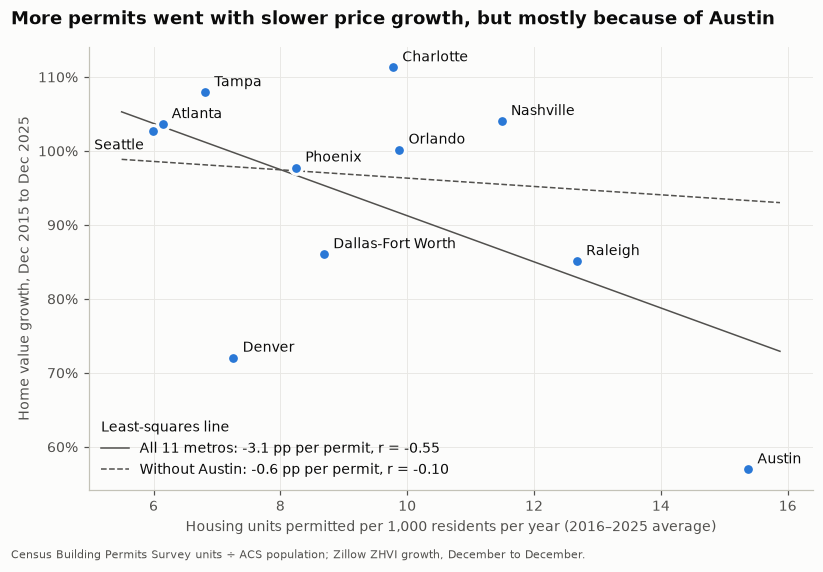

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 5))
xs = np.linspace(d.permits_per_1000.min() - 0.5, d.permits_per_1000.max() + 0.5, 2)
for f, style, label in [
    (fit, "-", "All 11 metros"),
    (fit_rest, "--", f"Without {top}"),
]:
    ax.plot(
        xs,
        f["intercept"] + f["slope"] * xs,
        style,
        color=c.INK2,
        lw=1,
        label=f"{label}: {f['slope'] * 100:+.1f} pp per permit, r = {f['r']:.2f}",
    )
ax.scatter(
    d.permits_per_1000,
    d.zhvi_growth,
    s=60,
    color=c.BLUE,
    edgecolor=c.SURFACE,
    linewidth=2,
    zorder=3,
)
offsets = {
    "Seattle": (-6, -12),
    "Atlanta": (6, 4),
}  # the two sit almost on top of each other
for m, r in d.iterrows():
    dx, dy = offsets.get(m, (6, 4))
    ax.annotate(
        m,
        (r.permits_per_1000, r.zhvi_growth),
        xytext=(dx, dy),
        textcoords="offset points",
        ha="right" if dx < 0 else "left",
        color=c.INK,
    )
ax.legend(loc="lower left", frameon=False, title="Least-squares line", alignment="left")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel(
    "Housing units permitted per 1,000 residents per year (2016–2025 average)"
)
ax.set_ylabel("Home value growth, Dec 2015 to Dec 2025")
c.save(
    fig,
    "q2_permits_vs_growth",
    "More permits went with slower price growth, but mostly because of Austin",
    "Census Building Permits Survey units ÷ ACS population; Zillow ZHVI growth, December to December.",
)

## Answer

In [4]:
print(
    f"Across 11 metros, each extra housing unit permitted per 1,000 residents per year in 2016–2025 went with "
    f"{-fit['slope'] * 100:.1f} percentage points less home value growth over the decade (r = {fit['r']:.2f}), "
    f"but {top}, the top builder at {d.permits_per_1000[top]:.1f} per 1,000 a year and the slowest grower "
    f"({d.zhvi_growth[top]:.0%}), carries the line: without it the slope is {fit_rest['slope'] * 100:+.1f} pp "
    f"(r = {fit_rest['r']:.2f})."
)

Across 11 metros, each extra housing unit permitted per 1,000 residents per year in 2016–2025 went with 3.1 percentage points less home value growth over the decade (r = -0.55), but Austin, the top builder at 15.4 per 1,000 a year and the slowest grower (57%), carries the line: without it the slope is -0.6 pp (r = -0.10).
